# Engines & Parameter Sweeps

Two engines run the same object model. `engine="python"` is the default and the
reference implementation. `engine="cpp"` moves the event loop and book keeping into a
compiled extension. Strategies can stay in Python, or be written in C++ for the
largest gain.

Both engines must produce identical trades for the same strategy.
`StrategyRunner.run_batch` sweeps parameters in parallel on either.

In [1]:
import time
import warnings
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd

import yabte.utilities.pandas_extension  # registers the .prc accessor
from yabte.backtest import Book, StrategyRunner, find_missing_data
from yabte.backtest.runner_cpp import yabte_cpp
from yabte.tests._helpers import generate_nasdaq_dataset

# strategies used with run_batch must be importable by worker processes,
# so this one lives in a module next to the notebook (see section 3)
from example_strategies import SMAXO

HAS_CPP = yabte_cpp is not None
print("C++ engine available:", HAS_CPP)

assets, df_combined = generate_nasdaq_dataset()
print(f"{len(assets)} assets, {len(df_combined)} days")

# the sample data's last day is missing most closing prices; a backtest raises
# MissingPriceError if an order fills, or a held position is valued, without a
# price, so drop it
missing = find_missing_data(df_combined, assets)
display(missing.groupby("asset_name").ts.agg(["min", "max", "count"]))
df_combined = df_combined.iloc[:-1]

C++ engine available: True
8 assets, 1259 days


,min,max,count
asset_name,,,
AAPL,2022-12-30,2022-12-30,1
AMZN,2022-12-30,2022-12-30,1
INTC,2022-12-30,2022-12-30,1
META,2022-12-30,2022-12-30,1
NFLX,2022-12-30,2022-12-30,1
TSLA,2022-12-30,2022-12-30,1


`yabte_cpp` is `None` when the extension isn't built (a pure-Python install, for
example), and `engine="cpp"` then raises. PyPI wheels include it. The C++ cells below
skip themselves without it.

## 1. Same strategy, either engine

Only `engine=` changes. `SMAXO` is a plain Python moving average crossover from
`example_strategies.py`.

In [2]:
def run(engine, strategies, params=None):
    sr = StrategyRunner(
        data=df_combined,
        assets=assets,
        strategies=strategies,
        books=[Book(name="Main", cash=Decimal("1000000"))],
        engine=engine,
    )
    start = time.perf_counter()
    srr = sr.run(params)
    return srr, time.perf_counter() - start


def trades(srr):
    """Trades in a canonical order, for comparing engines."""
    th = srr.transaction_history
    return (
        pd.DataFrame(
            {
                # the engines return different timestamp resolutions
                "ts": pd.to_datetime(th.ts).values.astype("datetime64[ns]"),
                "asset": th.asset_name.values,
                "quantity": th.quantity.astype(float).values,
                "price": th.price.astype(float).values,
            }
        )
        .sort_values(["ts", "asset"])
        .reset_index(drop=True)
    )


params = {"days_short": 10, "days_long": 20}
srr_py, t_py = run("python", [SMAXO()], params)
print(f"python engine: {t_py:.2f}s, {len(srr_py.transaction_history)} trades")

if HAS_CPP:
    srr_cpp, t_cpp = run("cpp", [SMAXO()], params)
    print(f"cpp engine:    {t_cpp:.2f}s, {len(srr_cpp.transaction_history)} trades")
    pd.testing.assert_frame_equal(trades(srr_py), trades(srr_cpp))
    print("identical trades")

python engine: 15.62s, 541 trades


cpp engine:    14.63s, 541 trades
identical trades


Both return a `StrategyRunnerResult` with the same `book_history` and
`transaction_history`.

With a Python strategy, the strategy dominates the run time. Every
`on_open`/`on_close` call crosses back into Python and slices a pandas window of
`self.data`. Precompute signals with numpy in `init()` and look them up per step to get
more out of the C++ engine.

## 2. Native C++ strategies

A C++ strategy never calls back into Python. The extension ships one example.
`SMAXOStrategy(asset_name, short, long)` runs the same crossover on a single asset, so
one instance per asset reproduces the Python strategy.

cpp engine, native strategies: 0.016s
identical trades


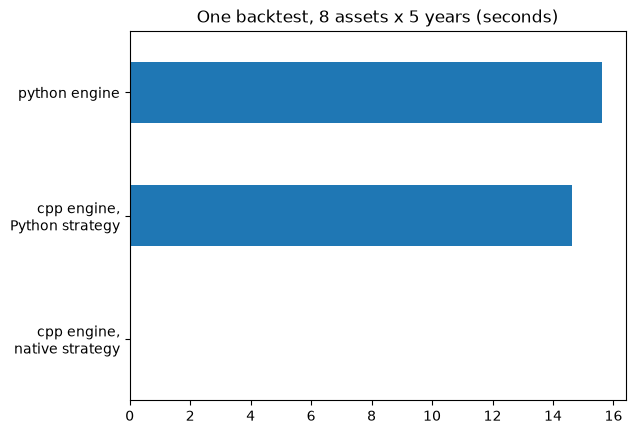

In [3]:
if HAS_CPP:
    symbols = [a.name for a in assets]
    native = [yabte_cpp.SMAXOStrategy(s, 10, 20) for s in symbols]
    srr_native, t_native = run("cpp", native)
    print(f"cpp engine, native strategies: {t_native:.3f}s")
    pd.testing.assert_frame_equal(trades(srr_py), trades(srr_native))
    print("identical trades")

    timings = pd.Series(
        {
            "python engine": t_py,
            "cpp engine,\nPython strategy": t_cpp,
            "cpp engine,\nnative strategy": t_native,
        }
    )
    ax = timings.plot.barh(title="One backtest, 8 assets x 5 years (seconds)")
    ax.invert_yaxis()

New native strategies subclass `Strategy` in C++ (see `cpp/`) and are exposed through
the pybind11 module. The gap widens with more assets.
`python -m yabte.tests.benchmark.benchmark_cpp_vs_py` benchmarks the engines on
synthetic data of any size.

## 3. C++ engine limitations

The C++ engine converts assets, books and orders to its own types. Some Python
features don't survive the conversion:

| Feature | C++ engine |
|---|---|
| Book mandates (`BookMandate`) | raises `ValueError` |
| `BasketOrder` / `PositionalBasketOrder` | raises `NotImplementedError` |
| Custom `Asset` subclasses | priced as `OHLCAsset` |
| Custom order subclasses (e.g. overriding `pre_execute_check` or `post_complete`) | sent as the base `SimpleOrder` / `PositionalOrder` |

Mandates and baskets fail loudly. Custom assets and orders silently lose their
overrides. Strategies that depend on them need `engine="python"` (see
[Orders & Assets](Orders_and_Assets.ipynb)).

In [4]:
from yabte.backtest import BasketOrder, BookMandate, Strategy


class NoShorts(BookMandate):
    def check(self, current_pos, quantity):
        return current_pos + quantity >= 0


class BuyBasket(Strategy):
    def on_open(self):
        if len(self.data) == 1:
            self.orders.append(
                BasketOrder(asset_names=["AAPL", "MSFT"], weights=[1, 1], size=10)
            )


if HAS_CPP:
    for label, kwargs in [
        (
            "mandate",
            dict(
                strategies=[SMAXO()],
                books=[Book(name="Main", mandates={"AAPL": NoShorts()})],
            ),
        ),
        ("basket order", dict(strategies=[BuyBasket()])),
    ]:
        try:
            StrategyRunner(
                data=df_combined.iloc[:5], assets=assets, engine="cpp", **kwargs
            ).run()
        except (ValueError, NotImplementedError) as e:
            print(f"{label}: {type(e).__name__}: {e}")

mandate: ValueError: Mandates are not supported in C++ mode.
basket order: NotImplementedError: BasketOrder is not supported by the C++ engine; use engine="python" for this strategy.


## 4. Parameter sweeps with `run_batch`

`run_batch` runs the strategies once per parameter set and returns results in input
order. Strategies read their parameters from `self.params`.

In [5]:
grid = [
    {"days_short": s, "days_long": l} for s in (5, 10, 15, 20) for l in (30, 50, 100)
]

sr = StrategyRunner(
    data=df_combined,
    assets=assets,
    strategies=[SMAXO()],
    books=[Book(name="Main", cash=Decimal("1000000"))],
)

start = time.perf_counter()
srrs = sr.run_batch(grid)
t_batch = time.perf_counter() - start

# a plain loop, [sr.run(p) for p in grid], takes about one run's time per parameter set
print(
    f"{len(grid)} runs: run_batch {t_batch:.1f}s, "
    f"plain loop ~{len(grid) * t_py:.0f}s (one run took {t_py:.1f}s)"
)

12 runs: run_batch 30.0s, plain loop ~187s (one run took 15.6s)


Without an `executor`, `run_batch` chooses for you:

- **Python strategies**, on either engine, go to a **process pool** with one worker per
  CPU. Each worker receives the data once. Threads would hold the GIL during strategy
  code and run slower than a plain loop.
- **Native C++ strategies with `engine="cpp"`** use the C++ thread pool over one shared
  copy of the data.

Processes impose two constraints.

1. Workers must **import the strategy class**, hence `SMAXO` living in
   `example_strategies.py`. A class defined in a notebook cell or a function can't be
   imported. `run_batch` warns and falls back to running serially:

In [6]:
class NotebookSMAXO(SMAXO):
    pass


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    StrategyRunner(
        data=df_combined.iloc[:60], assets=assets, strategies=[NotebookSMAXO()]
    ).run_batch(grid[:2])
print(caught[0].message)

run_batch is running serially because strategy class NotebookSMAXO is defined interactively (e.g. in a notebook). Define strategy classes at module level in an importable module to run in parallel, or pass an executor.


2. **Scripts** calling `run_batch` need the multiprocessing guard, since every worker
   re-imports the main module:

```python
if __name__ == "__main__":
    results = runner.run_batch(grid)
```

To control parallelism yourself, pass any `concurrent.futures.Executor`
(`run_batch(grid, executor=ProcessPoolExecutor(4))`). It's used as given and shut down
afterwards.

### Comparing the results

Every result is a full `StrategyRunnerResult`. Here, the annualised Sharpe ratio of
each book's total value:

days_long,30,50,100
days_short,,,
5,0.291569,0.172882,0.239388
10,0.095519,0.135423,0.326126
15,0.068919,-0.060048,0.401203
20,0.051861,-0.115277,0.387989


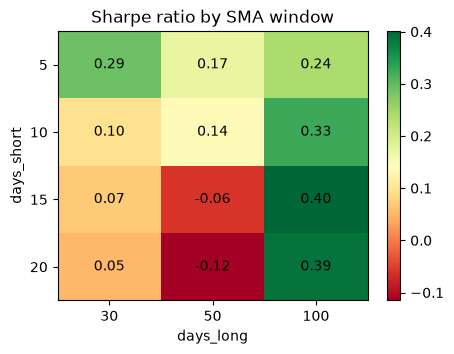

In [7]:
sharpe = pd.Series(
    [srr.book_history.loc[:, ("Main", "total")].prc.sharpe_ratio() for srr in srrs],
    index=pd.MultiIndex.from_tuples(
        [(p["days_short"], p["days_long"]) for p in grid],
        names=["days_short", "days_long"],
    ),
).unstack()

fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.imshow(sharpe.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(sharpe.columns)), sharpe.columns)
ax.set_yticks(range(len(sharpe.index)), sharpe.index)
ax.set_xlabel("days_long")
ax.set_ylabel("days_short")
for (i, j), v in pd.DataFrame(sharpe.values).stack().items():
    ax.text(j, i, f"{v:.2f}", ha="center", va="center")
ax.set_title("Sharpe ratio by SMA window")
fig.colorbar(im)
sharpe

### Sweeping native C++ strategies

Native strategies take their settings in the constructor, not from `self.params`.
Sweep them with one runner per parameter set; each run is fast enough for a plain loop.
`run_batch` with only native strategies would run identical copies on the C++ thread
pool. That only helps when the strategy reads `params` itself.

In [8]:
if HAS_CPP:
    start = time.perf_counter()
    native_sharpe = {}
    for p in grid:
        srr, _ = run(
            "cpp",
            [
                yabte_cpp.SMAXOStrategy(s, p["days_short"], p["days_long"])
                for s in symbols
            ],
        )
        native_sharpe[p["days_short"], p["days_long"]] = srr.book_history.loc[
            :, ("Main", "total")
        ].prc.sharpe_ratio()
    print(f"{len(grid)} native runs: {time.perf_counter() - start:.2f}s")

    # same Sharpe ratios as the Python sweep
    pd.testing.assert_frame_equal(
        pd.Series(native_sharpe).unstack(), sharpe, check_names=False
    )
    print("same Sharpe ratios as the Python sweep")

12 native runs: 0.25s
same Sharpe ratios as the Python sweep
